# LQ45 Systematic Backtesting Engine

Proyek ini membangun *backtesting engine* untuk menguji strategi trading aktif secara sistematis pada 44 saham konstituen LQ45, yaitu saham-saham dengan likuiditas dan kapitalisasi pasar tertinggi yang tercatat di Bursa Efek Indonesia, menggunakan pendekatan walk-forward validation untuk menghindari overfitting.

Tahapan yang dilakukan:
1. **Data collection & cleaning** — download harga historis 44 saham LQ45 dan indeks pasar (IHSG)
2. **Strategy signal generation** — konstruksi aturan trading aktif berbasis MA Crossover (momentum/trend-following)
3. **Walk-forward validation** — pembagian data menjadi window train/test bergulir untuk menguji strategi pada data out-of-sample
4. **Backtesting simulation** — simulasi eksekusi strategi lengkap dengan transaction cost dan slippage
5. **Performance evaluation** — pengukuran metrik performa (return, Sharpe ratio, max drawdown, win rate) per window backtest
6. **Visualisasi & insight** — equity curve, perbandingan performa antar window, dan analisis konsistensi strategi

Output akhir adalah evaluasi performa strategi trading secara out-of-sample beserta insight mengenai konsistensi dan robustness strategi di berbagai kondisi pasar.

## Section 1: Setup & Data Collection

Notebook ini membangun **Systematic Backtesting Engine** untuk menguji strategi trading aktif (dimulai dengan MA Crossover) pada universe 44 saham LQ45, dengan walk-forward validation sebagai metode utama untuk menghindari overfitting.

Universe dan periode data mengikuti Project 3 (Risk Management Dashboard): 44 saham LQ45 (AADI dikeluarkan karena data tidak lengkap) ditambah benchmark, periode 13 September 2024 – 11 September 2026 (477 hari trading).

Section ini melakukan:
1. Import library yang dibutuhkan
2. Definisi universe saham dan periode data
3. Fetch data harga historis via `yfinance`
4. Pengecekan awal (shape, rentang tanggal, missing values)

In [4]:
# ============================================================
# SECTION 1: SETUP & DATA COLLECTION
# ============================================================

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')

# ------------------------------------------------------------
# Universe: 44 LQ45 constituents (AADI dropped, per Project 3)
# ------------------------------------------------------------
tickers = [
    'ADMR', 'ADRO', 'AKRA', 'AMMN', 'AMRT', 'ANTM', 'ASII', 'BBCA', 'BBNI',
    'BBRI', 'BBTN', 'BMRI', 'BRPT', 'BUMI', 'CPIN', 'CUAN', 'DEWA', 'EMTK',
    'ESSA', 'EXCL', 'GOTO', 'HRTA', 'ICBP', 'INCO', 'INDF', 'INDY', 'INKP',
    'ISAT', 'ITMG', 'JPFA', 'KLBF', 'MAPI', 'MBMA', 'MDKA', 'MEDC', 'NCKL',
    'PGAS', 'PGEO', 'PTBA', 'SCMA', 'TLKM', 'UNTR', 'UNVR', 'WIFI'
]

tickers_yf = [t + '.JK' for t in tickers]
benchmark = '^JKSE'  # IHSG, konsisten dengan Project 3

start_date = '2024-09-13'
end_date = '2026-09-16'

# ------------------------------------------------------------
# Fetch data
# ------------------------------------------------------------
print("Downloading stock price data...")
raw_data = yf.download(tickers_yf, start=start_date, end=end_date)['Close']
raw_data.columns = tickers  # strip .JK suffix

print("Downloading benchmark index data...")
benchmark_data = yf.download(benchmark, start=start_date, end=end_date)['Close']

# ------------------------------------------------------------
# Sanity check
# ------------------------------------------------------------
print(f"\nShape: {raw_data.shape}")
print(f"Date range: {raw_data.index.min()} to {raw_data.index.max()}")
print(f"Missing values per stock:\n{raw_data.isna().sum().sort_values(ascending=False).head(10)}")

[*********************100%***********************]  44 of 44 completed
[*********************100%***********************]  1 of 1 completed


Shape: (479, 44)
Date range: 2024-09-13 00:00:00 to 2026-09-15 00:00:00
Missing values per stock:
ADMR    1
CUAN    1
PGEO    1
NCKL    1
MDKA    1
MBMA    1
INDY    1
ADRO    1
HRTA    1
GOTO    1
dtype: int64


## Section 2: Data Cleaning

Section ini membersihkan data harga yang sudah didownload sebelum dipakai untuk generate trading signal dan backtesting. Proses meliputi pengecekan missing values, penanganan gap kecil (forward-fill), dan validasi ulang bahwa seluruh saham punya data yang cukup lengkap untuk periode backtest.

Langkah yang dilakukan:
1. Cek jumlah missing value per saham
2. Drop saham dengan missing value signifikan (indikasi listing terlambat atau suspend berkepanjangan)
3. Forward-fill untuk gap kecil (tidak ada transaksi 1-2 hari)
4. Gabungkan data saham dan benchmark ke dalam satu dataframe, pastikan index tanggal selaras
5. Hitung return harian sebagai dasar untuk signal generation & backtesting

In [5]:
# ============================================================
# SECTION 2: DATA CLEANING
# ============================================================

# ------------------------------------------------------------
# 1. Cek missing value per saham
# ------------------------------------------------------------
missing_counts = raw_data.isna().sum().sort_values(ascending=False)
print("Missing values per saham:")
print(missing_counts[missing_counts > 0])

# ------------------------------------------------------------
# 2. Drop saham dengan missing value signifikan (>5% dari total hari)
# ------------------------------------------------------------
threshold = 0.05 * len(raw_data)
stocks_to_drop = missing_counts[missing_counts > threshold].index.tolist()

if stocks_to_drop:
    print(f"\nSaham di-drop karena missing value signifikan: {stocks_to_drop}")
    raw_data = raw_data.drop(columns=stocks_to_drop)
else:
    print("\nTidak ada saham yang di-drop, semua di bawah threshold missing value.")

# ------------------------------------------------------------
# 3. Forward-fill untuk gap kecil yang tersisa
# ------------------------------------------------------------
clean_data = raw_data.ffill()
benchmark_clean = benchmark_data.ffill()

# Drop baris awal yang masih NaN (sebelum saham mulai listing/trading)
clean_data = clean_data.dropna()

# ------------------------------------------------------------
# 4. Selaraskan tanggal saham dan benchmark
# ------------------------------------------------------------
common_dates = clean_data.index.intersection(benchmark_clean.index)
clean_data = clean_data.loc[common_dates]
benchmark_clean = benchmark_clean.loc[common_dates]

print(f"\nFinal shape: {clean_data.shape}")
print(f"Final date range: {clean_data.index.min()} to {clean_data.index.max()}")
print(f"Jumlah saham final: {clean_data.shape[1]}")

# ------------------------------------------------------------
# 5. Hitung return harian
# ------------------------------------------------------------
returns = clean_data.pct_change().dropna()
benchmark_returns = benchmark_clean.pct_change().dropna()

print(f"\nShape returns: {returns.shape}")
returns.head()

Missing values per saham:
ADMR    1
CUAN    1
PGEO    1
NCKL    1
MDKA    1
MBMA    1
INDY    1
ADRO    1
HRTA    1
GOTO    1
EXCL    1
ESSA    1
EMTK    1
DEWA    1
ICBP    1
CPIN    1
BBCA    1
AKRA    1
AMMN    1
AMRT    1
WIFI    1
BBTN    1
dtype: int64

Tidak ada saham yang di-drop, semua di bawah threshold missing value.

Final shape: (474, 44)
Final date range: 2024-09-13 00:00:00 to 2026-09-15 00:00:00
Jumlah saham final: 44

Shape returns: (473, 44)


,ADMR,ADRO,AKRA,AMMN,AMRT,ANTM,ASII,BBCA,BBNI,BBRI,BBTN,BMRI,BRPT,BUMI,CPIN,CUAN,DEWA,EMTK,ESSA,EXCL,GOTO,HRTA,ICBP,INCO,INDF,INDY,INKP,ISAT,ITMG,JPFA,KLBF,MAPI,MBMA,MDKA,MEDC,NCKL,PGAS,PGEO,PTBA,SCMA,TLKM,UNTR,UNVR,WIFI
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-09-17,0.026923,0.024523,0.006803,-0.004843,0.000000,0.033708,0.000000,0.007194,0.004444,0.000000,0.010489,0.020619,0.004386,0.060606,0.033333,0.002817,0.031250,-0.009756,0.000000,-0.012931,0.065574,0.000000,0.006623,0.013624,0.000000,0.000000,-0.011940,-0.004598,-0.013359,0.016234,0.000000,0.078313,0.000000,0.004367,0.004081,0.011561,0.000000,0.000000,0.025641,0.008265,-0.006431,0.012334,-0.009091,0.060606
2024-09-18,-0.007491,-0.029255,-0.010135,0.009732,0.003175,-0.010870,0.034483,0.011905,0.008850,0.009434,0.027682,-0.003367,-0.004367,0.000000,-0.004032,-0.011236,0.000000,0.024631,-0.012195,-0.004367,-0.061538,-0.005181,0.008772,-0.010753,-0.003521,-0.016722,0.006042,-0.013857,0.002901,-0.012780,0.026393,0.005587,-0.027778,-0.008696,0.000000,0.000000,0.003344,0.000000,-0.007143,-0.016394,0.009709,0.001874,0.013761,-0.014286
2024-09-19,0.026415,0.002740,0.003413,0.004819,-0.012658,0.007326,0.004762,0.025882,0.021930,0.009346,0.033670,0.000000,0.048246,0.114286,0.022267,0.005682,0.030303,-0.014423,-0.012346,0.008772,0.032787,0.015625,0.017391,0.002717,0.000000,0.017007,0.000000,-0.002342,0.002893,0.000000,-0.011429,-0.011111,0.009524,-0.004386,0.020325,0.000000,-0.013333,0.004464,0.000000,0.008333,0.006410,-0.003742,-0.004525,0.007246
2024-09-20,-0.007353,0.008197,0.017007,-0.009592,0.000000,-0.003636,-0.009479,-0.011468,-0.012876,-0.004629,-0.003257,-0.013514,-0.108787,-0.008547,-0.009901,-0.180791,0.000000,-0.039024,0.000000,-0.008696,0.000000,0.000000,0.025641,0.002710,0.010601,-0.016722,-0.012012,0.000000,-0.003846,0.009709,-0.005780,0.039326,0.018868,-0.004405,0.007968,0.017143,0.006757,-0.008889,0.061151,0.008265,0.003185,0.011268,-0.013636,-0.014389
2024-09-23,-0.014815,0.002710,0.016723,-0.014528,0.032051,0.018248,0.000000,0.016241,0.008696,0.023256,0.000000,0.020548,0.009390,0.068966,-0.008000,0.062069,0.058824,0.030457,0.025000,0.008772,0.031746,0.010256,0.016667,0.013514,-0.006993,0.074830,0.009119,0.028169,0.010618,-0.012821,0.008721,-0.021622,0.009259,0.013274,-0.007905,0.011236,0.000000,0.031390,0.057627,-0.008197,0.006349,0.007428,0.018433,0.000000


## Section 3: Strategy Signal Generation (MA Crossover)

Section ini membangun sinyal trading aktif berbasis **Moving Average Crossover**, salah satu strategi momentum/trend-following paling klasik. Sinyal *buy* muncul ketika moving average jangka pendek memotong ke atas moving average jangka panjang (golden cross), dan sinyal *sell* muncul saat sebaliknya (death cross).

Strategi ini dipilih sebagai aturan aktif pertama karena logikanya sederhana dan mudah diverifikasi, sehingga fokus dapat diarahkan ke validitas *engine*-nya (walk-forward validation, transaction cost, slippage) di section berikutnya, bukan ke kompleksitas strategi itu sendiri.

Langkah yang dilakukan:
1. Hitung moving average jangka pendek (misal 20 hari) dan jangka panjang (misal 50 hari) untuk tiap saham
2. Generate sinyal posisi: 1 (long) saat MA pendek > MA panjang, 0 (flat) saat sebaliknya
3. Hitung jumlah crossover event per saham sebagai sanity check awal
4. Visualisasi contoh sinyal pada salah satu saham

Jumlah crossover event per saham (top 10):
SCMA    18
ANTM    14
ESSA    13
AKRA    13
AMRT    12
ADRO    12
ITMG    11
EMTK    11
INDY    11
BMRI    11
dtype: int64

Rata-rata crossover event per saham: 9.2


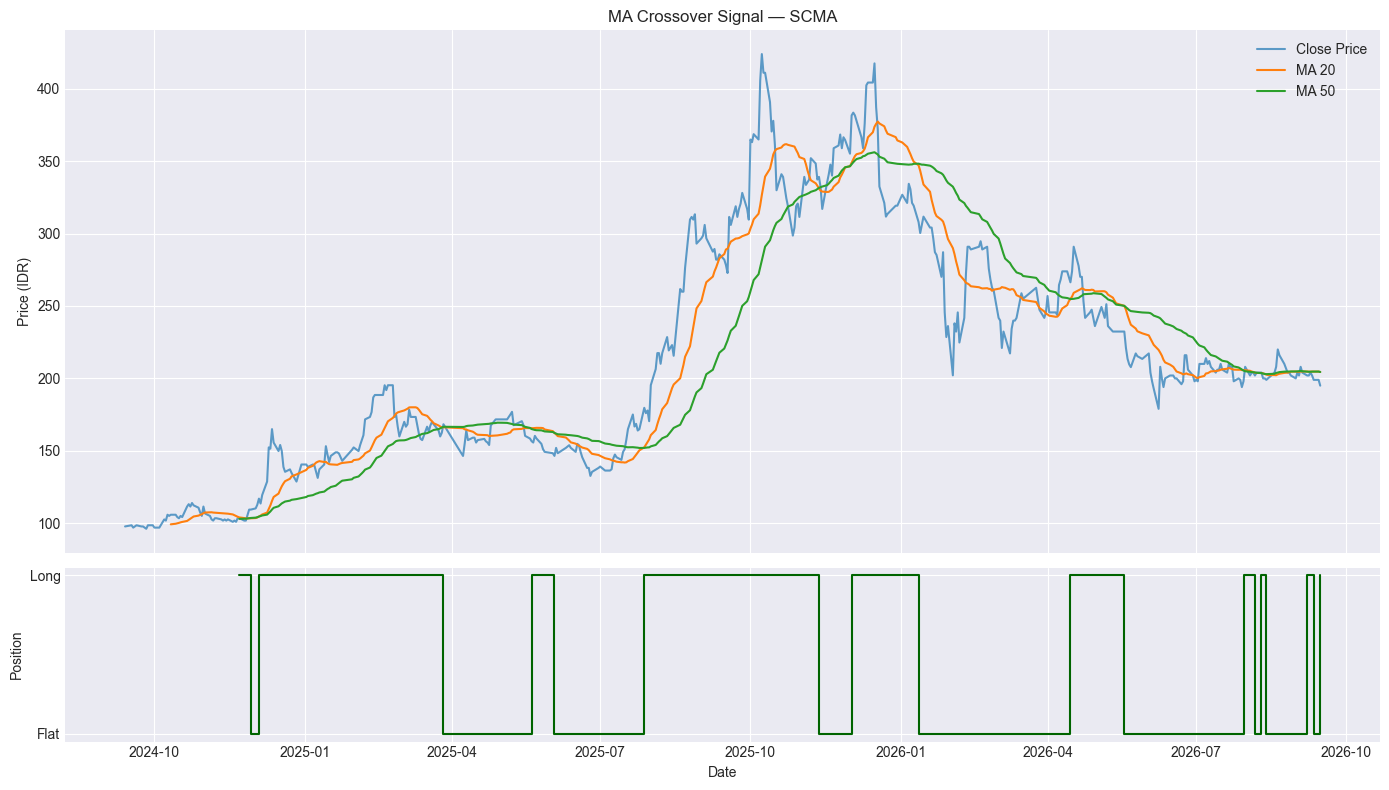

In [6]:
# ============================================================
# SECTION 3: STRATEGY SIGNAL GENERATION (MA CROSSOVER)
# ============================================================

short_window = 20
long_window = 50

# ------------------------------------------------------------
# 1. Hitung moving average jangka pendek & panjang
# ------------------------------------------------------------
ma_short = clean_data.rolling(window=short_window).mean()
ma_long = clean_data.rolling(window=long_window).mean()

# ------------------------------------------------------------
# 2. Generate sinyal posisi (1 = long, 0 = flat)
# ------------------------------------------------------------
signals = pd.DataFrame(index=clean_data.index, columns=clean_data.columns)
signals[:] = np.where(ma_short > ma_long, 1, 0)
signals = signals.astype(int)

# Drop baris awal yang masih NaN (belum cukup data untuk MA panjang)
valid_start = ma_long.dropna(how='all').index.min()
signals = signals.loc[valid_start:]

# ------------------------------------------------------------
# 3. Hitung jumlah crossover event per saham
# ------------------------------------------------------------
crossover_counts = (signals.diff().fillna(0) != 0).sum().sort_values(ascending=False)
print("Jumlah crossover event per saham (top 10):")
print(crossover_counts.head(10))
print(f"\nRata-rata crossover event per saham: {crossover_counts.mean():.1f}")

# ------------------------------------------------------------
# 4. Visualisasi contoh sinyal (saham dengan crossover terbanyak)
# ------------------------------------------------------------
sample_stock = crossover_counts.index[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})

axes[0].plot(clean_data.index, clean_data[sample_stock], label='Close Price', alpha=0.7)
axes[0].plot(ma_short.index, ma_short[sample_stock], label=f'MA {short_window}', linewidth=1.5)
axes[0].plot(ma_long.index, ma_long[sample_stock], label=f'MA {long_window}', linewidth=1.5)
axes[0].set_title(f'MA Crossover Signal — {sample_stock}')
axes[0].set_ylabel('Price (IDR)')
axes[0].legend()

axes[1].plot(signals.index, signals[sample_stock], drawstyle='steps-post', color='darkgreen')
axes[1].set_ylabel('Position')
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(['Flat', 'Long'])
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

## Section 4: Walk-Forward Validation Setup

Section ini membangun kerangka **walk-forward validation** — teknik utama untuk mencegah overfitting dalam backtesting. Alih-alih menguji strategi sekali di seluruh data historis (yang rawan bias, karena parameter bisa "kebetulan cocok" dengan pola masa lalu), data dibagi menjadi beberapa window train/test yang bergerak maju secara berurutan (rolling), meniru bagaimana strategi akan benar-benar dipakai di dunia nyata: parameter dioptimasi pakai data lampau, lalu diuji pada data yang belum pernah dilihat.

Skema yang dipakai:
- **Train window**: 250 hari trading (~1 tahun) — untuk optimasi parameter MA (short/long window)
- **Test window**: 60 hari trading (~3 bulan) — untuk menguji parameter hasil optimasi di data out-of-sample
- **Step**: window bergeser maju 60 hari setiap iterasi (non-overlapping test window)

Langkah yang dilakukan:
1. Fungsi untuk generate index rentang train/test per window
2. Loop untuk membuat seluruh window walk-forward berdasarkan panjang data yang tersedia
3. Ringkasan jumlah window yang terbentuk beserta rentang tanggalnya

In [7]:
# ============================================================
# SECTION 4: WALK-FORWARD VALIDATION SETUP
# ============================================================

train_window = 250   # hari trading (~1 tahun) untuk optimasi parameter
test_window = 60      # hari trading (~3 bulan) untuk evaluasi out-of-sample
step = test_window    # window test tidak overlap antar iterasi

def generate_walk_forward_windows(dates, train_window, test_window, step):
    """
    Generate list of (train_start, train_end, test_start, test_end) index positions
    berdasarkan rolling window walk-forward.
    """
    windows = []
    n = len(dates)
    start = 0

    while True:
        train_start = start
        train_end = train_start + train_window
        test_start = train_end
        test_end = test_start + test_window

        if test_end > n:
            break

        windows.append({
            'train_start_date': dates[train_start],
            'train_end_date': dates[train_end - 1],
            'test_start_date': dates[test_start],
            'test_end_date': dates[test_end - 1],
            'train_idx': (train_start, train_end),
            'test_idx': (test_start, test_end)
        })

        start += step

    return windows

# ------------------------------------------------------------
# Generate seluruh window walk-forward
# ------------------------------------------------------------
dates = returns.index
wf_windows = generate_walk_forward_windows(dates, train_window, test_window, step)

print(f"Total window walk-forward yang terbentuk: {len(wf_windows)}\n")
for i, w in enumerate(wf_windows):
    print(f"Window {i+1}: Train [{w['train_start_date'].date()} - {w['train_end_date'].date()}] "
          f"→ Test [{w['test_start_date'].date()} - {w['test_end_date'].date()}]")

Total window walk-forward yang terbentuk: 3

Window 1: Train [2024-09-17 - 2025-10-07] → Test [2025-10-08 - 2026-01-05]
Window 2: Train [2024-12-11 - 2026-01-05] → Test [2026-01-06 - 2026-04-10]
Window 3: Train [2025-03-14 - 2026-04-10] → Test [2026-04-13 - 2026-07-14]


## Section 5: Parameter Optimization & Backtest per Window

Section ini menjalankan inti dari backtesting engine: untuk setiap window walk-forward, parameter MA Crossover (kombinasi short/long window) dioptimasi menggunakan data **train** (mencari kombinasi dengan Sharpe ratio terbaik), lalu parameter terbaik tersebut diterapkan dan dievaluasi di data **test** (out-of-sample).

Simulasi juga memperhitungkan **transaction cost** dan **slippage**, karena tanpa itu hasil backtest bisa terlalu optimis (di dunia nyata, tiap kali crossover terjadi dan posisi berubah, ada biaya transaksi yang mengurangi return).

Langkah yang dilakukan:
1. Fungsi untuk menghitung return strategi (dengan transaction cost) dari kombinasi parameter MA tertentu
2. Fungsi grid search parameter optimal berdasarkan Sharpe ratio di data train
3. Loop utama: untuk tiap window, optimasi di train → terapkan & evaluasi di test
4. Kumpulkan hasil tiap window (parameter terpilih, performa test) ke dalam satu tabel ringkasan

In [8]:
# ============================================================
# SECTION 5: PARAMETER OPTIMIZATION & BACKTEST PER WINDOW
# ============================================================

transaction_cost = 0.0015   # 0.15% per transaksi (buy/sell), estimasi biaya broker + slippage IDX
risk_free_rate = 0.055      # asumsi BI rate tahunan, dari Project 2/3
trading_days = 252

# Grid parameter yang akan dicoba
short_windows = [5, 10, 15, 20]
long_windows = [30, 50, 75, 100]

# ------------------------------------------------------------
# 1. Fungsi hitung return strategi untuk satu kombinasi parameter
# ------------------------------------------------------------
def backtest_strategy(price_data, ret_data, short_w, long_w, cost):
    ma_s = price_data.rolling(window=short_w).mean()
    ma_l = price_data.rolling(window=long_w).mean()

    position = pd.DataFrame(
        np.where(ma_s > ma_l, 1, 0),
        index=price_data.index, columns=price_data.columns
    )
    position = position.shift(1)  # sinyal dipakai hari berikutnya (hindari lookahead bias)

    strategy_returns = position * ret_data

    # Transaction cost: dikenakan tiap kali posisi berubah
    position_change = position.diff().abs().fillna(0)
    cost_impact = position_change * cost
    strategy_returns_net = strategy_returns - cost_impact

    return strategy_returns_net.dropna(how='all')

# ------------------------------------------------------------
# 2. Fungsi hitung Sharpe ratio portofolio equal-weight dari strategy returns
# ------------------------------------------------------------
def portfolio_sharpe(strategy_returns, rf, periods=252):
    port_ret = strategy_returns.mean(axis=1)  # equal-weight across stocks
    excess_ret = port_ret.mean() * periods - rf
    vol = port_ret.std() * np.sqrt(periods)
    return excess_ret / vol if vol > 0 else -np.inf, port_ret

# ------------------------------------------------------------
# 3. Grid search parameter optimal di data TRAIN
# ------------------------------------------------------------
def optimize_parameters(price_train, ret_train, short_windows, long_windows, cost, rf):
    best_sharpe = -np.inf
    best_params = None

    for s in short_windows:
        for l in long_windows:
            if s >= l:
                continue  # short window harus lebih kecil dari long window
            strat_ret = backtest_strategy(price_train, ret_train, s, l, cost)
            if strat_ret.empty:
                continue
            sharpe, _ = portfolio_sharpe(strat_ret, rf)
            if sharpe > best_sharpe:
                best_sharpe = sharpe
                best_params = (s, l)

    return best_params, best_sharpe

# ------------------------------------------------------------
# 4. Loop utama: optimasi per window (train) → evaluasi (test)
# ------------------------------------------------------------
window_results = []

for i, w in enumerate(wf_windows):
    train_start, train_end = w['train_idx']
    test_start, test_end = w['test_idx']

    price_train = clean_data.iloc[train_start:train_end]
    ret_train = returns.iloc[train_start:train_end]

    price_test = clean_data.iloc[test_start:test_end]
    ret_test = returns.iloc[test_start:test_end]

    # Optimasi parameter di train
    best_params, train_sharpe = optimize_parameters(
        price_train, ret_train, short_windows, long_windows,
        transaction_cost, risk_free_rate
    )

    if best_params is None:
        print(f"Window {i+1}: tidak ditemukan parameter valid, skip.")
        continue

    s_opt, l_opt = best_params

    # Terapkan parameter terbaik ke data test (out-of-sample)
    # Perlu price_test dgn buffer sebelumnya supaya MA di awal test window tidak NaN
    buffer_start = max(0, test_start - l_opt)
    price_test_buffered = clean_data.iloc[buffer_start:test_end]
    ret_test_buffered = returns.iloc[buffer_start:test_end]

    strat_ret_test = backtest_strategy(price_test_buffered, ret_test_buffered, s_opt, l_opt, transaction_cost)
    strat_ret_test = strat_ret_test.loc[strat_ret_test.index.isin(ret_test.index)]

    test_sharpe, port_ret_test = portfolio_sharpe(strat_ret_test, risk_free_rate)

    total_return = (1 + port_ret_test).prod() - 1
    cum_ret = (1 + port_ret_test).cumprod()
    max_dd = (cum_ret / cum_ret.cummax() - 1).min()
    win_rate = (port_ret_test > 0).mean()

    window_results.append({
        'window': i + 1,
        'test_start': w['test_start_date'].date(),
        'test_end': w['test_end_date'].date(),
        'ma_short': s_opt,
        'ma_long': l_opt,
        'train_sharpe': round(train_sharpe, 3),
        'test_sharpe': round(test_sharpe, 3),
        'test_total_return': round(total_return * 100, 2),
        'test_max_drawdown': round(max_dd * 100, 2),
        'test_win_rate': round(win_rate * 100, 1)
    })

# ------------------------------------------------------------
# Ringkasan hasil
# ------------------------------------------------------------
results_df = pd.DataFrame(window_results)
print("Hasil Walk-Forward Backtest per Window:\n")
print(results_df.to_string(index=False))

Hasil Walk-Forward Backtest per Window:

 window test_start   test_end  ma_short  ma_long  train_sharpe  test_sharpe  test_total_return  test_max_drawdown  test_win_rate
      1 2025-10-08 2026-01-05        10       75         2.337        2.436               7.96              -2.52           54.2
      2 2026-01-06 2026-04-10         5       75         2.753       -0.505              -1.32              -9.29           54.2
      3 2026-04-13 2026-07-14         5       30         1.862       -5.093              -8.79             -11.34           39.0


## Section 6: Equity Curve & Robustness Visualization

Section ini memvisualisasikan hasil walk-forward backtest secara gabungan (concatenated equity curve dari ketiga window test secara berurutan) dan membandingkannya dengan performa buy & hold sebagai baseline. Visualisasi ini membantu melihat secara langsung ketidakkonsistenan performa antar window yang sudah terlihat di tabel Section 5.

Langkah yang dilakukan:
1. Gabungkan return strategi dari seluruh window test menjadi satu equity curve kontinu
2. Hitung equity curve baseline (buy & hold equal-weight, periode yang sama)
3. Plot equity curve strategi vs baseline, dengan penanda batas antar window
4. Bar chart perbandingan Sharpe ratio per window (train vs test) untuk menegaskan pola overfitting
5. Ringkasan robustness: rata-rata dan standar deviasi test Sharpe antar window

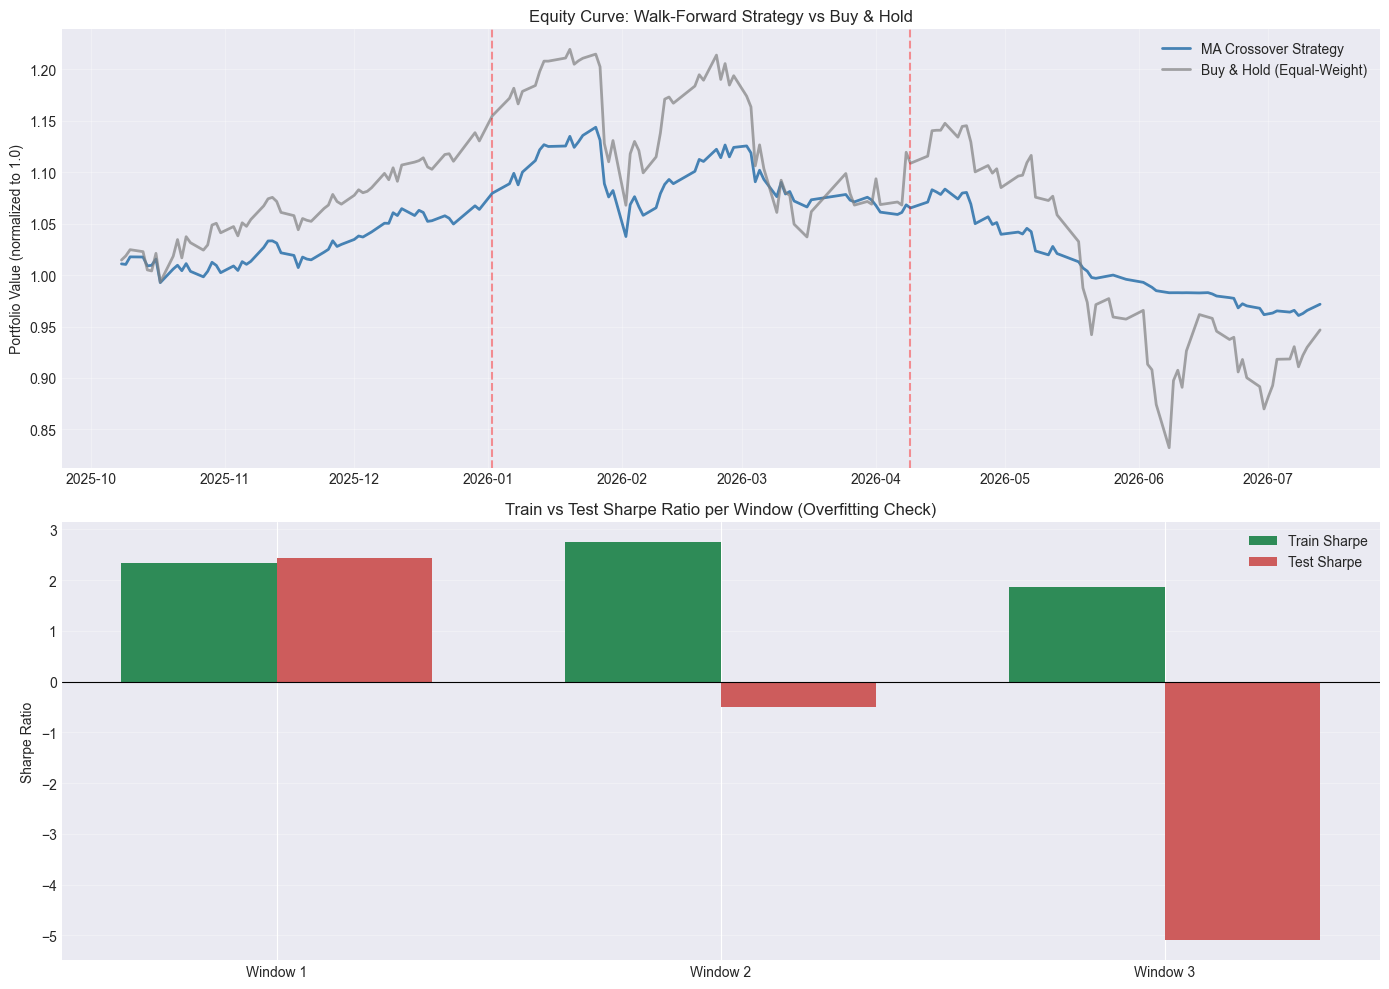

Ringkasan Robustness Strategi:

Rata-rata Train Sharpe : 2.317
Rata-rata Test Sharpe  : -1.054
Std Dev Test Sharpe    : 3.794
Test Sharpe positif    : 1 dari 3 window

Strategy Total Return (gabungan test) : -2.83%
Buy & Hold Total Return (periode sama) : -5.33%


In [9]:
# ============================================================
# SECTION 6: EQUITY CURVE & ROBUSTNESS VISUALIZATION
# ============================================================

# ------------------------------------------------------------
# 1. Gabungkan return strategi dari seluruh window test
# ------------------------------------------------------------
all_test_returns = []
window_boundaries = []

for i, w in enumerate(wf_windows):
    test_start, test_end = w['test_idx']
    s_opt, l_opt = window_results[i]['ma_short'], window_results[i]['ma_long']

    buffer_start = max(0, test_start - l_opt)
    price_test_buffered = clean_data.iloc[buffer_start:test_end]
    ret_test_buffered = returns.iloc[buffer_start:test_end]

    strat_ret_test = backtest_strategy(price_test_buffered, ret_test_buffered, s_opt, l_opt, transaction_cost)
    ret_test_actual = returns.iloc[test_start:test_end]
    strat_ret_test = strat_ret_test.loc[strat_ret_test.index.isin(ret_test_actual.index)]

    port_ret = strat_ret_test.mean(axis=1)
    all_test_returns.append(port_ret)
    window_boundaries.append(port_ret.index[-1])

combined_strategy_returns = pd.concat(all_test_returns)
combined_strategy_returns = combined_strategy_returns[~combined_strategy_returns.index.duplicated()]
strategy_equity = (1 + combined_strategy_returns).cumprod()

# ------------------------------------------------------------
# 2. Baseline: Buy & Hold equal-weight, periode sama dengan gabungan test
# ------------------------------------------------------------
bh_period_returns = returns.loc[combined_strategy_returns.index]
bh_port_returns = bh_period_returns.mean(axis=1)
bh_equity = (1 + bh_port_returns).cumprod()

# ------------------------------------------------------------
# 3. Plot equity curve strategi vs baseline
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(strategy_equity.index, strategy_equity, label='MA Crossover Strategy', linewidth=2, color='steelblue')
axes[0].plot(bh_equity.index, bh_equity, label='Buy & Hold (Equal-Weight)', linewidth=2, color='gray', alpha=0.7)

for boundary in window_boundaries[:-1]:
    axes[0].axvline(boundary, color='red', linestyle='--', alpha=0.4)

axes[0].set_title('Equity Curve: Walk-Forward Strategy vs Buy & Hold')
axes[0].set_ylabel('Portfolio Value (normalized to 1.0)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# ------------------------------------------------------------
# 4. Bar chart Sharpe ratio per window (train vs test)
# ------------------------------------------------------------
x = np.arange(len(results_df))
width = 0.35

axes[1].bar(x - width/2, results_df['train_sharpe'], width, label='Train Sharpe', color='seagreen')
axes[1].bar(x + width/2, results_df['test_sharpe'], width, label='Test Sharpe', color='indianred')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels([f"Window {w}" for w in results_df['window']])
axes[1].set_ylabel('Sharpe Ratio')
axes[1].set_title('Train vs Test Sharpe Ratio per Window (Overfitting Check)')
axes[1].legend()
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Ringkasan robustness
# ------------------------------------------------------------
print("Ringkasan Robustness Strategi:\n")
print(f"Rata-rata Train Sharpe : {results_df['train_sharpe'].mean():.3f}")
print(f"Rata-rata Test Sharpe  : {results_df['test_sharpe'].mean():.3f}")
print(f"Std Dev Test Sharpe    : {results_df['test_sharpe'].std():.3f}")
print(f"Test Sharpe positif    : {(results_df['test_sharpe'] > 0).sum()} dari {len(results_df)} window")
print(f"\nStrategy Total Return (gabungan test) : {(strategy_equity.iloc[-1] - 1) * 100:.2f}%")
print(f"Buy & Hold Total Return (periode sama) : {(bh_equity.iloc[-1] - 1) * 100:.2f}%")

## Section 7: Insight & Conclusion

Section penutup ini merangkum temuan utama dari seluruh proses walk-forward backtesting terhadap strategi MA Crossover pada universe 44 saham LQ45, serta implikasinya sebagai bukti kerja engine backtesting yang dibangun.

**Ringkasan hasil:**
- Dari 3 window walk-forward, parameter MA optimal (hasil grid search di data train) berbeda-beda tiap window (10&75, 5&75, 5&30) — tidak ada satu kombinasi yang konsisten menang, mengindikasikan parameter tersebut overfit terhadap pola historis window masing-masing, bukan menangkap pola yang benar-benar repeatable.
- Rata-rata Sharpe ratio anjlok drastis dari train (2.317) ke test (-1.054), dengan standar deviasi test Sharpe yang sangat tinggi (3.794) — menunjukkan performa strategi sangat tidak konsisten antar kondisi pasar.
- Hanya 1 dari 3 window menghasilkan test Sharpe positif — secara statistik tidak cukup untuk menyimpulkan strategi ini reliably profitable.
- Meski demikian, total return gabungan strategi (-2.83%) lebih baik dibanding Buy & Hold (-5.33%) pada periode yang sama — strategi menunjukkan sifat defensif, terutama terlihat di Window 3 saat Buy & Hold mengalami penurunan tajam sementara strategi lebih landai.

**Insight utama:**
1. **MA Crossover murni tanpa penyesuaian tidak terbukti sebagai strategi profitable yang robust** — gap besar antara performa train dan test adalah bukti kuat overfitting, sebuah risiko nyata dalam strategi berbasis optimasi parameter historis.
2. **Walk-forward validation berhasil menjalankan fungsinya** — mendeteksi bahwa strategi yang "kelihatan bagus" di in-sample testing ternyata tidak reliable di out-of-sample, sesuatu yang tidak akan terlihat jika backtest dilakukan sekali saja pada seluruh data historis.
3. **Sifat defensif strategi** (mengurangi kerugian saat market turun tajam) adalah temuan terpisah dari soal profitability — MA Crossover berperan lebih sebagai risk-reduction mechanism (keluar dari pasar saat momentum negatif) dibanding sebagai alpha generator.
4. **Ukuran sampel window (3) tergolong kecil** akibat keterbatasan panjang data historis (2 tahun), yang membatasi kekuatan kesimpulan robustness — konsekuensi yang wajar disebutkan sebagai limitasi.

**Limitasi & pengembangan lanjutan:**
- Grid parameter terbatas pada 16 kombinasi; grid lebih luas atau metode optimasi lain (Bayesian optimization) dapat dieksplorasi
- Strategi tunggal (MA Crossover) belum dibandingkan dengan aturan aktif lain (mean reversion, multi-factor) untuk melihat apakah pola overfitting ini spesifik ke strategi ini atau berlaku umum
- Position sizing masih biner (all-in/all-out, equal-weight) — belum mempertimbangkan risk-adjusted position sizing (misal berdasarkan beta dari Project 3)
- Proyek berikutnya (Time Series Forecasting/ML) dapat mengeksplorasi apakah model prediktif berbasis data dapat menghasilkan sinyal yang lebih robust dibanding aturan berbasis indikator teknikal sederhana